# NLP Assignment 2 — Project 7: Kaggle Execution Pipeline

**Student Roll:** 23CS30073  
**Task:** LLM Hallucination Detection on HaluEval QA  
**Environment:** Kaggle Notebook (GPU T4 x2 or P100)

> ⚠️ **IMPORTANT KAGGLE SETTINGS (Right Sidebar):**
> 1. **Settings → Accelerator**: Select **GPU T4 x2** (or GPU P100).
> 2. **Settings → Internet**: Toggle to **Internet ON** (Required to clone GitHub repo and download Hugging Face models).

In [1]:
# Cell 1: Check GPU hardware & PyTorch device status
!nvidia-smi

import torch
print("\n" + "=" * 50)
print(f"CUDA Available : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name    : {torch.cuda.get_device_name(0)}")
    print(f"Device Count   : {torch.cuda.device_count()}")
print("=" * 50)

Fri Nov  6 18:34:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Cell 2: Setup Kaggle Working Directory & Clone Project Repository
import os
import shutil

# 1. Permanent working directory in Kaggle
KAGGLE_DIR = "/kaggle/working/NLP_Assignment_2"
os.makedirs(KAGGLE_DIR, exist_ok=True)

# 2. Enter the project folder
%cd /kaggle/working/NLP_Assignment_2

# 3. Clone or pull repo files directly into Kaggle working dir
if not os.path.exists("task1_colab.py"):
    !git clone https://github.com/ThilokT/NLP_Assignment_2.git .
else:
    !git pull origin main 2>/dev/null || true

print("\n✓ Working directory initialized:")
!pwd
!ls -la

/kaggle/working/NLP_Assignment_2
Cloning into '.'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 58 (delta 15), reused 54 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (58/58), 1.25 MiB | 10.01 MiB/s, done.
Resolving deltas: 100% (15/15), done.

✓ Working directory initialized:
/kaggle/working/NLP_Assignment_2
total 1360
drwxr-xr-x 6 root root   4096 Nov  6 18:35 .
drwxr-xr-x 4 root root   4096 Nov  6 18:35 ..
-rw-r--r-- 1 root root  16997 Nov  6 18:35 BEGINNER_GUIDE_HALLEVAL_DETECTION.md
drwxr-xr-x 5 root root   4096 Nov  6 18:35 code
-rw-r--r-- 1 root root   3801 Nov  6 18:35 COMMANDS.md
drwxr-xr-x 2 root root   4096 Nov  6 18:35 data
-rw-r--r-- 1 root root  61758 Nov  6 18:35 datasets_text.txt
-rw-r--r-- 1 root root  20990 Nov  6 18:35 Data-setup.ipynb
-rw-r--r-- 1 root root   2442 Nov  6 18:35 ENVIRONMENT_SETUP.md
drwxr-xr-x 8 root root   4096 Nov  6 18:35 .git
-rw-r

In [3]:
# Cell 3: Install Required Dependencies
!pip install -q transformers torch bert-score huggingface_hub accelerate pandas scikit-learn matplotlib joblib tqdm

In [4]:
# Cell 4: Hugging Face Authentication
import os
from huggingface_hub import login

# Authenticate for google/gemma-2-2b-it
# Retrieve token from environment, Kaggle secrets, or user prompt
token = os.environ.get("HF_TOKEN", "")
if not token:
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        pass
if not token:
    from getpass import getpass
    token = getpass("Enter your Hugging Face token: ")

os.environ["HF_TOKEN"] = token
login(token=token)
print("✓ Hugging Face authenticated successfully!")

Enter your Hugging Face token:  ········


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


✓ Hugging Face authenticated successfully!


---
## Task 1: Knowledge-Conditioned Token Probability & Entropy Detection (~1 min on T4 GPU)
*Checkpoints and plots save directly into `/kaggle/working/NLP_Assignment_2`.*

In [5]:
# Cell 5: Run Task 1
%cd /kaggle/working/NLP_Assignment_2
!python -u task1_colab.py

/kaggle/working/NLP_Assignment_2
   TASK 1 (COLAB): KNOWLEDGE-CONDITIONED HALLUCINATION DETECTION
Working Directory: /kaggle/working/NLP_Assignment_2
Data Directory:    /kaggle/working/NLP_Assignment_2/data
Checkpoints:       /kaggle/working/NLP_Assignment_2/checkpoints
Outputs:           /kaggle/working/NLP_Assignment_2/outputs
Timestamp:         2026-11-06 18:36:35

✓ Found existing sampled data and train/test split.
  Total QA pairs: 400
  Train: 320 questions → 640 scoring instances
  Test:  80 questions → 160 scoring instances
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.
✓ Hugging Face authenticated.

✓ GPU Detected: Tesla T4
  VRAM Total:   14.56 GB

Loading model: google/gemma-2-2b-it...
config.json: 100%|█████████████████████████████| 838/838 [00:00<00:00, 2.41MB/s]
tokenizer_config.json: 100%|███████████████| 47.0k/47.0k [00:00<00:00, 42.5MB/s]

tokenizer.json: downloading bytes:               

---
## Task 2: SelfCheckGPT (Resampling + BERTScore + DeBERTa NLI) (~18 mins on T4 GPU)
*Resamples and consistency scores save into checkpoints folder every 25 questions.*

In [6]:
# Cell 6: Run Task 2
%cd /kaggle/working/NLP_Assignment_2
!python -u task2_colab.py

/kaggle/working/NLP_Assignment_2
   TASK 2 (COLAB): OPTIMIZED SELFCHECKGPT HALLUCINATION DETECTOR
Working Directory: /kaggle/working/NLP_Assignment_2
Data Directory:    /kaggle/working/NLP_Assignment_2/data
Checkpoints:       /kaggle/working/NLP_Assignment_2/checkpoints
Outputs:           /kaggle/working/NLP_Assignment_2/outputs

✓ Found existing sampled data and train/test split.
  Total QA pairs: 400 | Train: 320 | Test: 80
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.
✓ Hugging Face authenticated.

[Step 1] Loading LLM (google/gemma-2-2b-it) for resampling...
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|████████████████████████| 288/288 [00:02<00:00, 99.15it/s]
✓ LLM loaded on GPU: Tesla T4 | Memory: 3.83 GB

Resampling 400 questions (N=20, T=1.2, top_p=0.95)...
  Resuming with 0 already cached.
Resampling: 100%|█████████████████████████████| 400/400 [09:57<00

---
## Task 3: Stacked Ensemble Meta-Classifiers & Bootstrap Evaluation (~1 min)
*Trains Logistic Regression, Random Forest, Gradient Boosting with 5-fold CV and 2000 bootstrap CIs.*

In [7]:
# Cell 7: Run Task 3
%cd /kaggle/working/NLP_Assignment_2
!python -u task3_colab.py

/kaggle/working/NLP_Assignment_2
   TASK 3 (COLAB): OPTIMIZED STACKED ENSEMBLE META-CLASSIFIER
Random seed:     42
Train split:     320 questions (640 instances)
Test split:      80 questions (160 instances)

--- Checkpoint Files Status ---
  ⚠️ Notice: Task 1 (Original)                   NOT found (task1_logprobs_entropy.json). Skipping.
  ✓ Found & loaded: Task 1 (v2 Knowledge-Conditioned)   (400 items from task1_v2_features.json)
  ⚠️ Notice: Task 2 (Original SelfCheck)         NOT found (task2_selfcheck_scores.json). Skipping.
  ✓ Found & loaded: Task 2 (v2 Advanced SelfCheck)      (400 items from task2_v2_scores.json)
                                                                                
Unified Feature Table Constructed:
  Train shape:          (640, 19)
  Test shape:           (160, 19)
  Total features (17):   ['kc_mean_log_prob', 'kc_mean_entropy', 'kc_sum_log_prob', 'kc_log_prob_variance', 'kc_entropy_variance', 'kc_min_log_prob', 'kc_max_entropy', 'kc_perplexity', 

---
## Results Display & Inline Plots

/kaggle/working/NLP_Assignment_2
=== FINAL COMPARISON TABLE (TEST SET AUC-PR WITH 95% BOOTSTRAP CI) ===


,Method,AUC-PR (test),95% CI low,95% CI high
0,Best Single Feature (kc_answer_token_count),0.9801,0.9598,0.9957
1,LR (All features),0.9985,0.9951,1.0000
2,RF (All features),0.9957,0.9875,1.0000
3,GBT (All features),0.9954,0.9863,1.0000
4,Best Ensemble (LR (All features)),0.9985,0.9951,1.0000



Plot: outputs/task3_v2_pr_curves.png


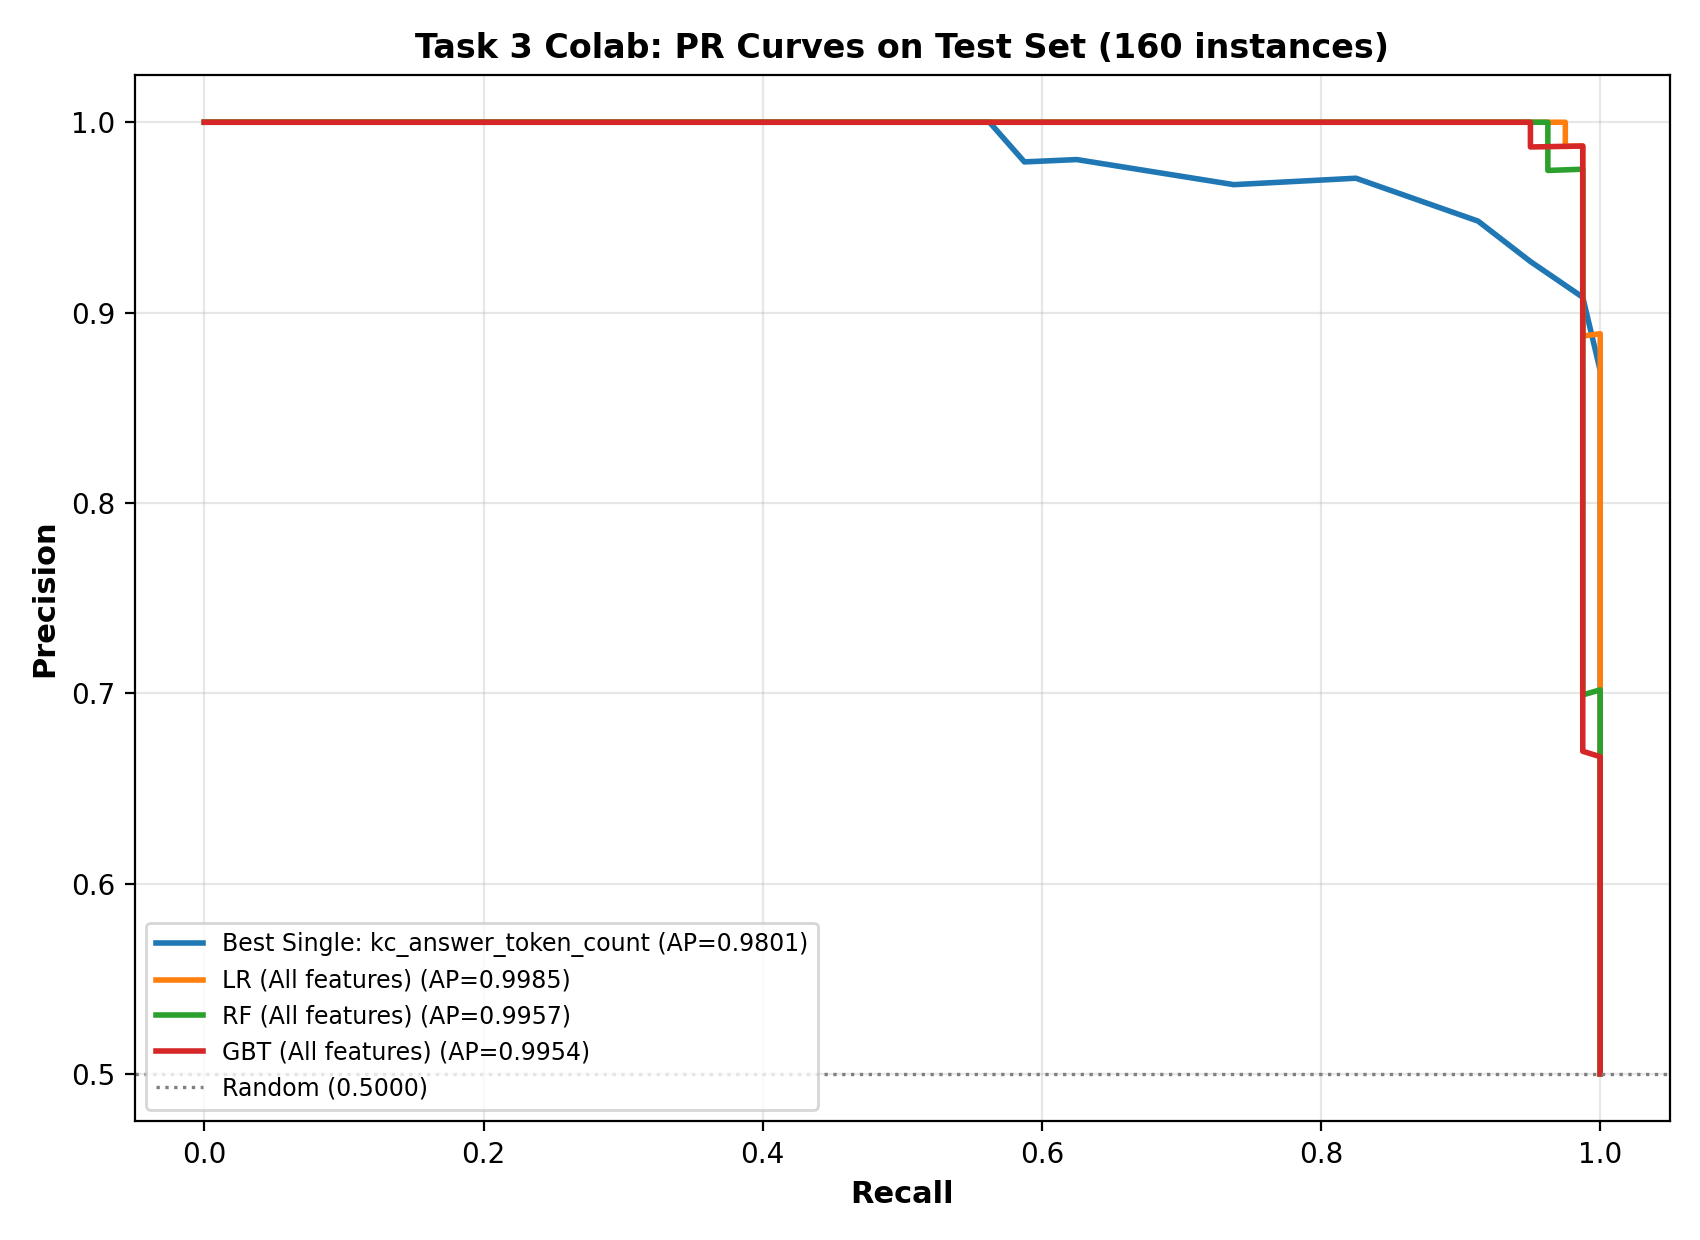


Plot: outputs/task1_v2_plots.png


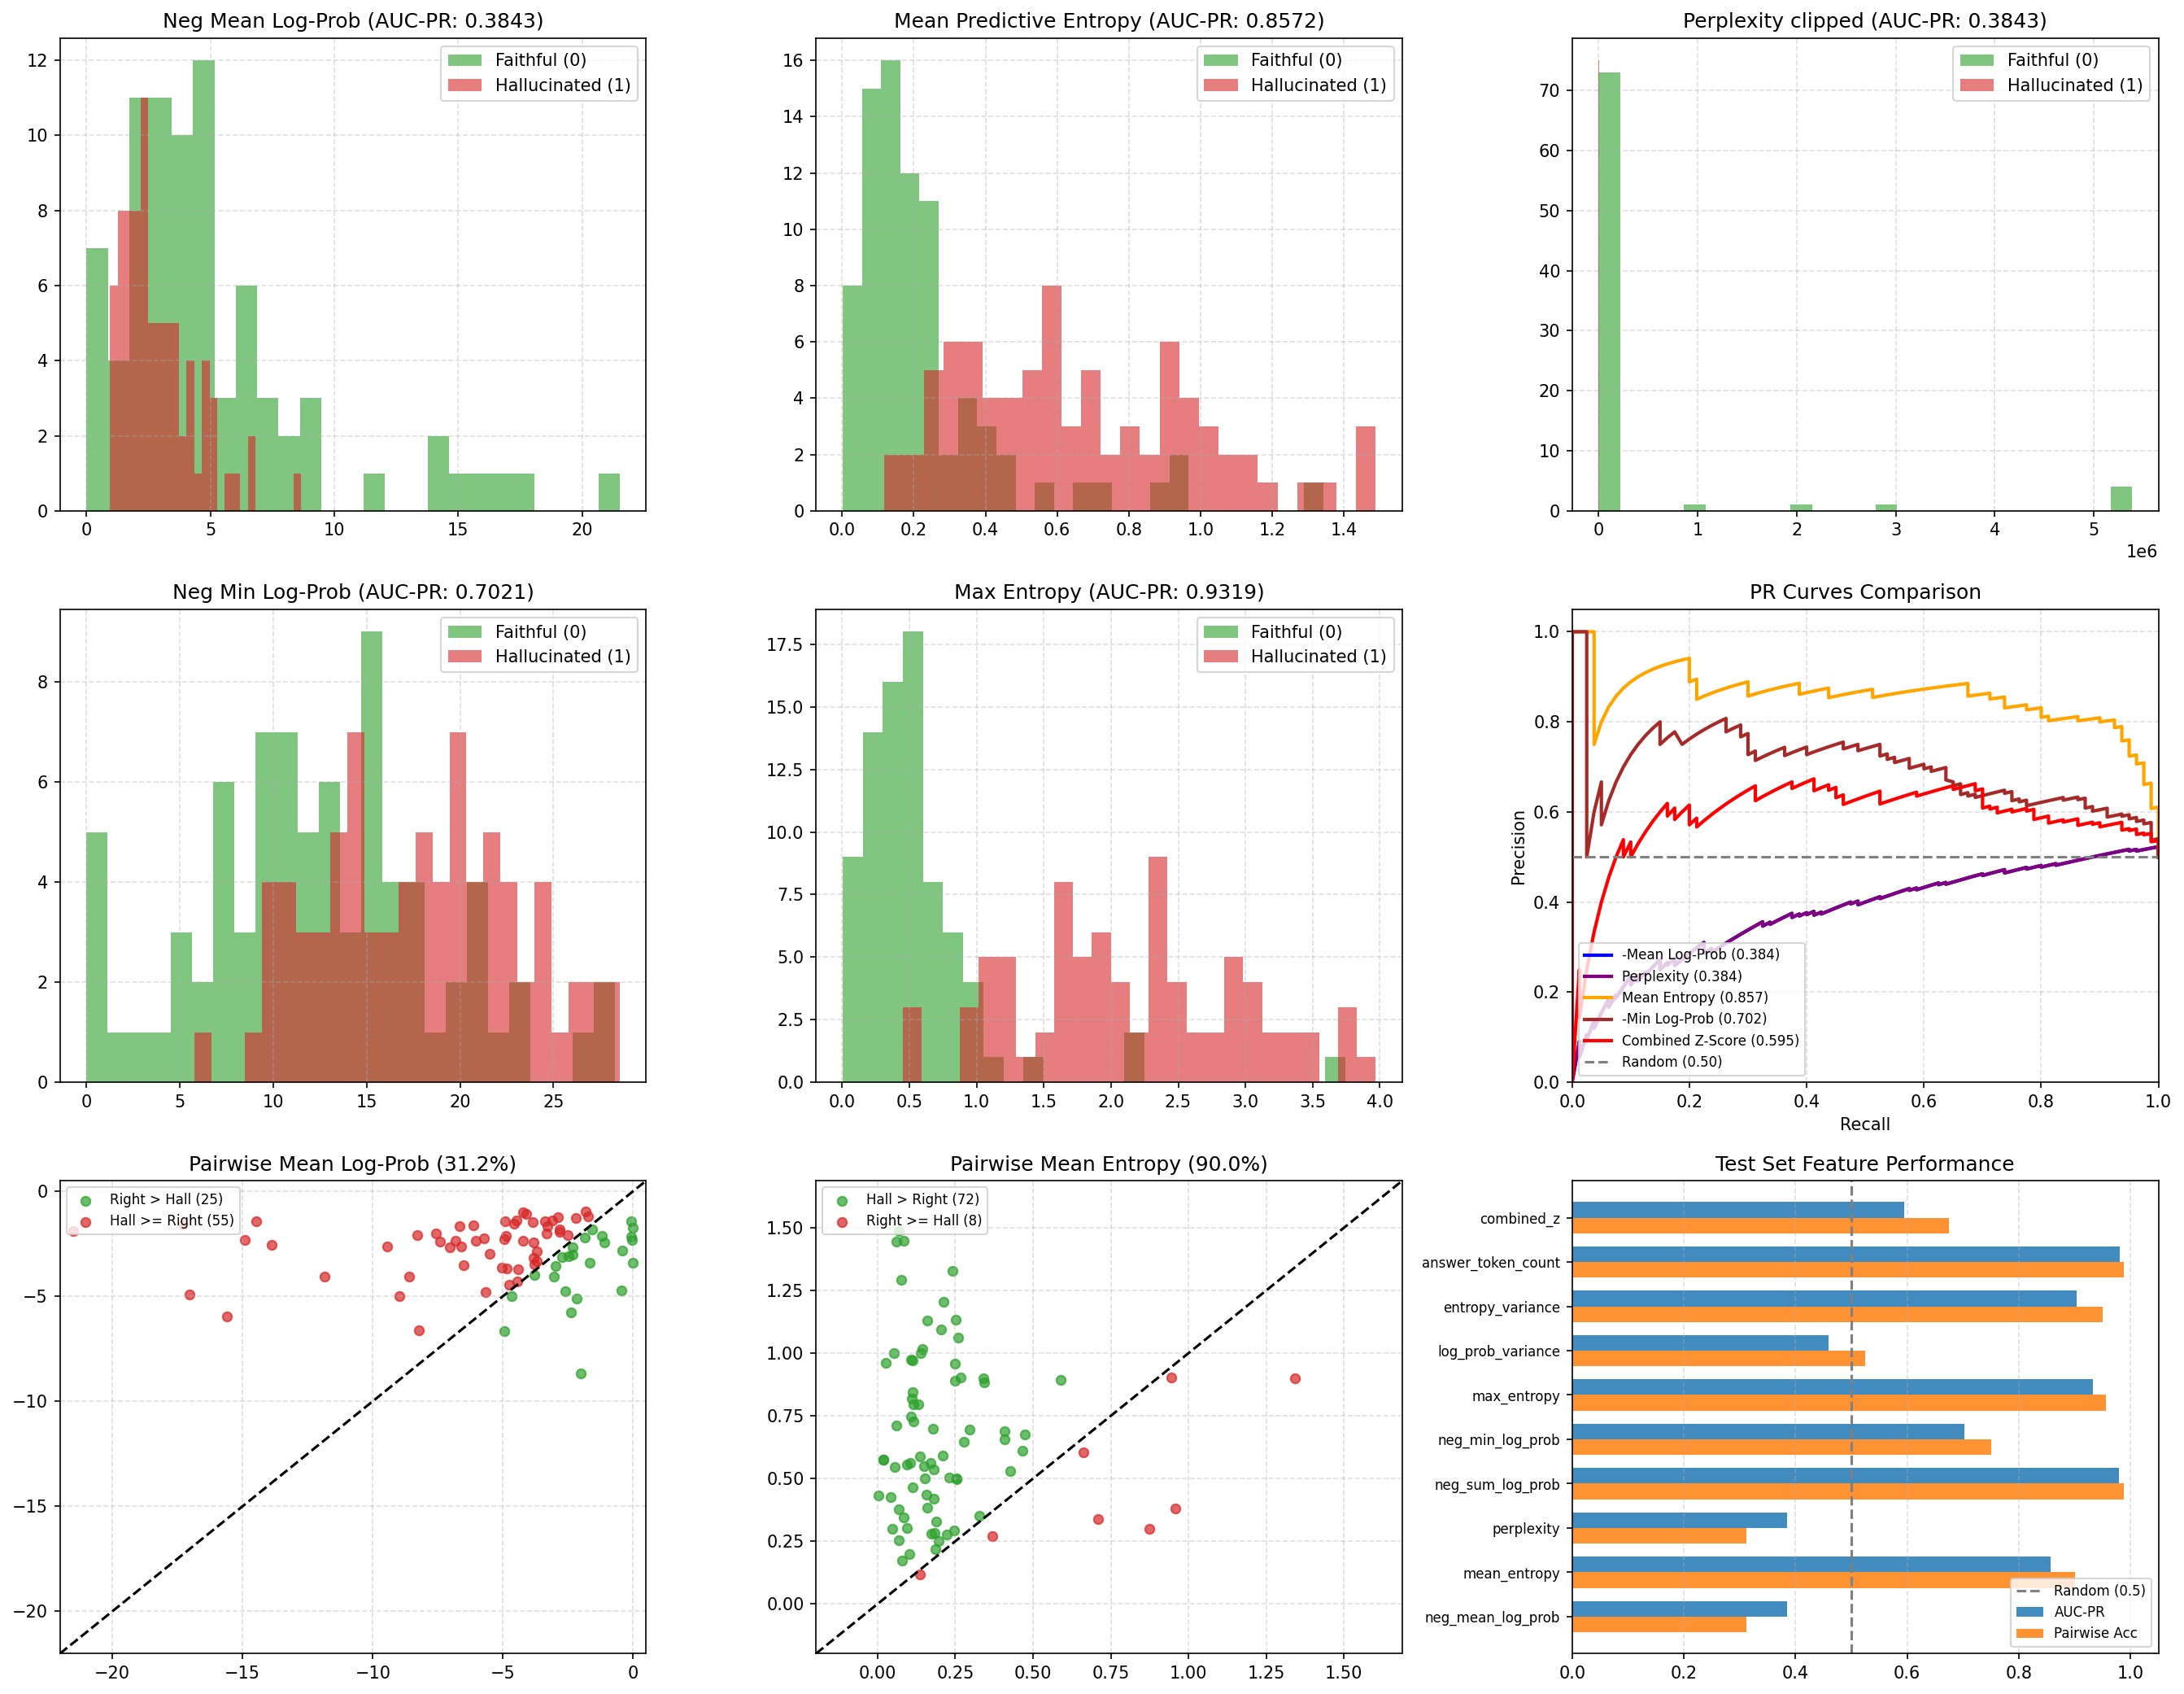


Plot: outputs/task2_v2_plots.png


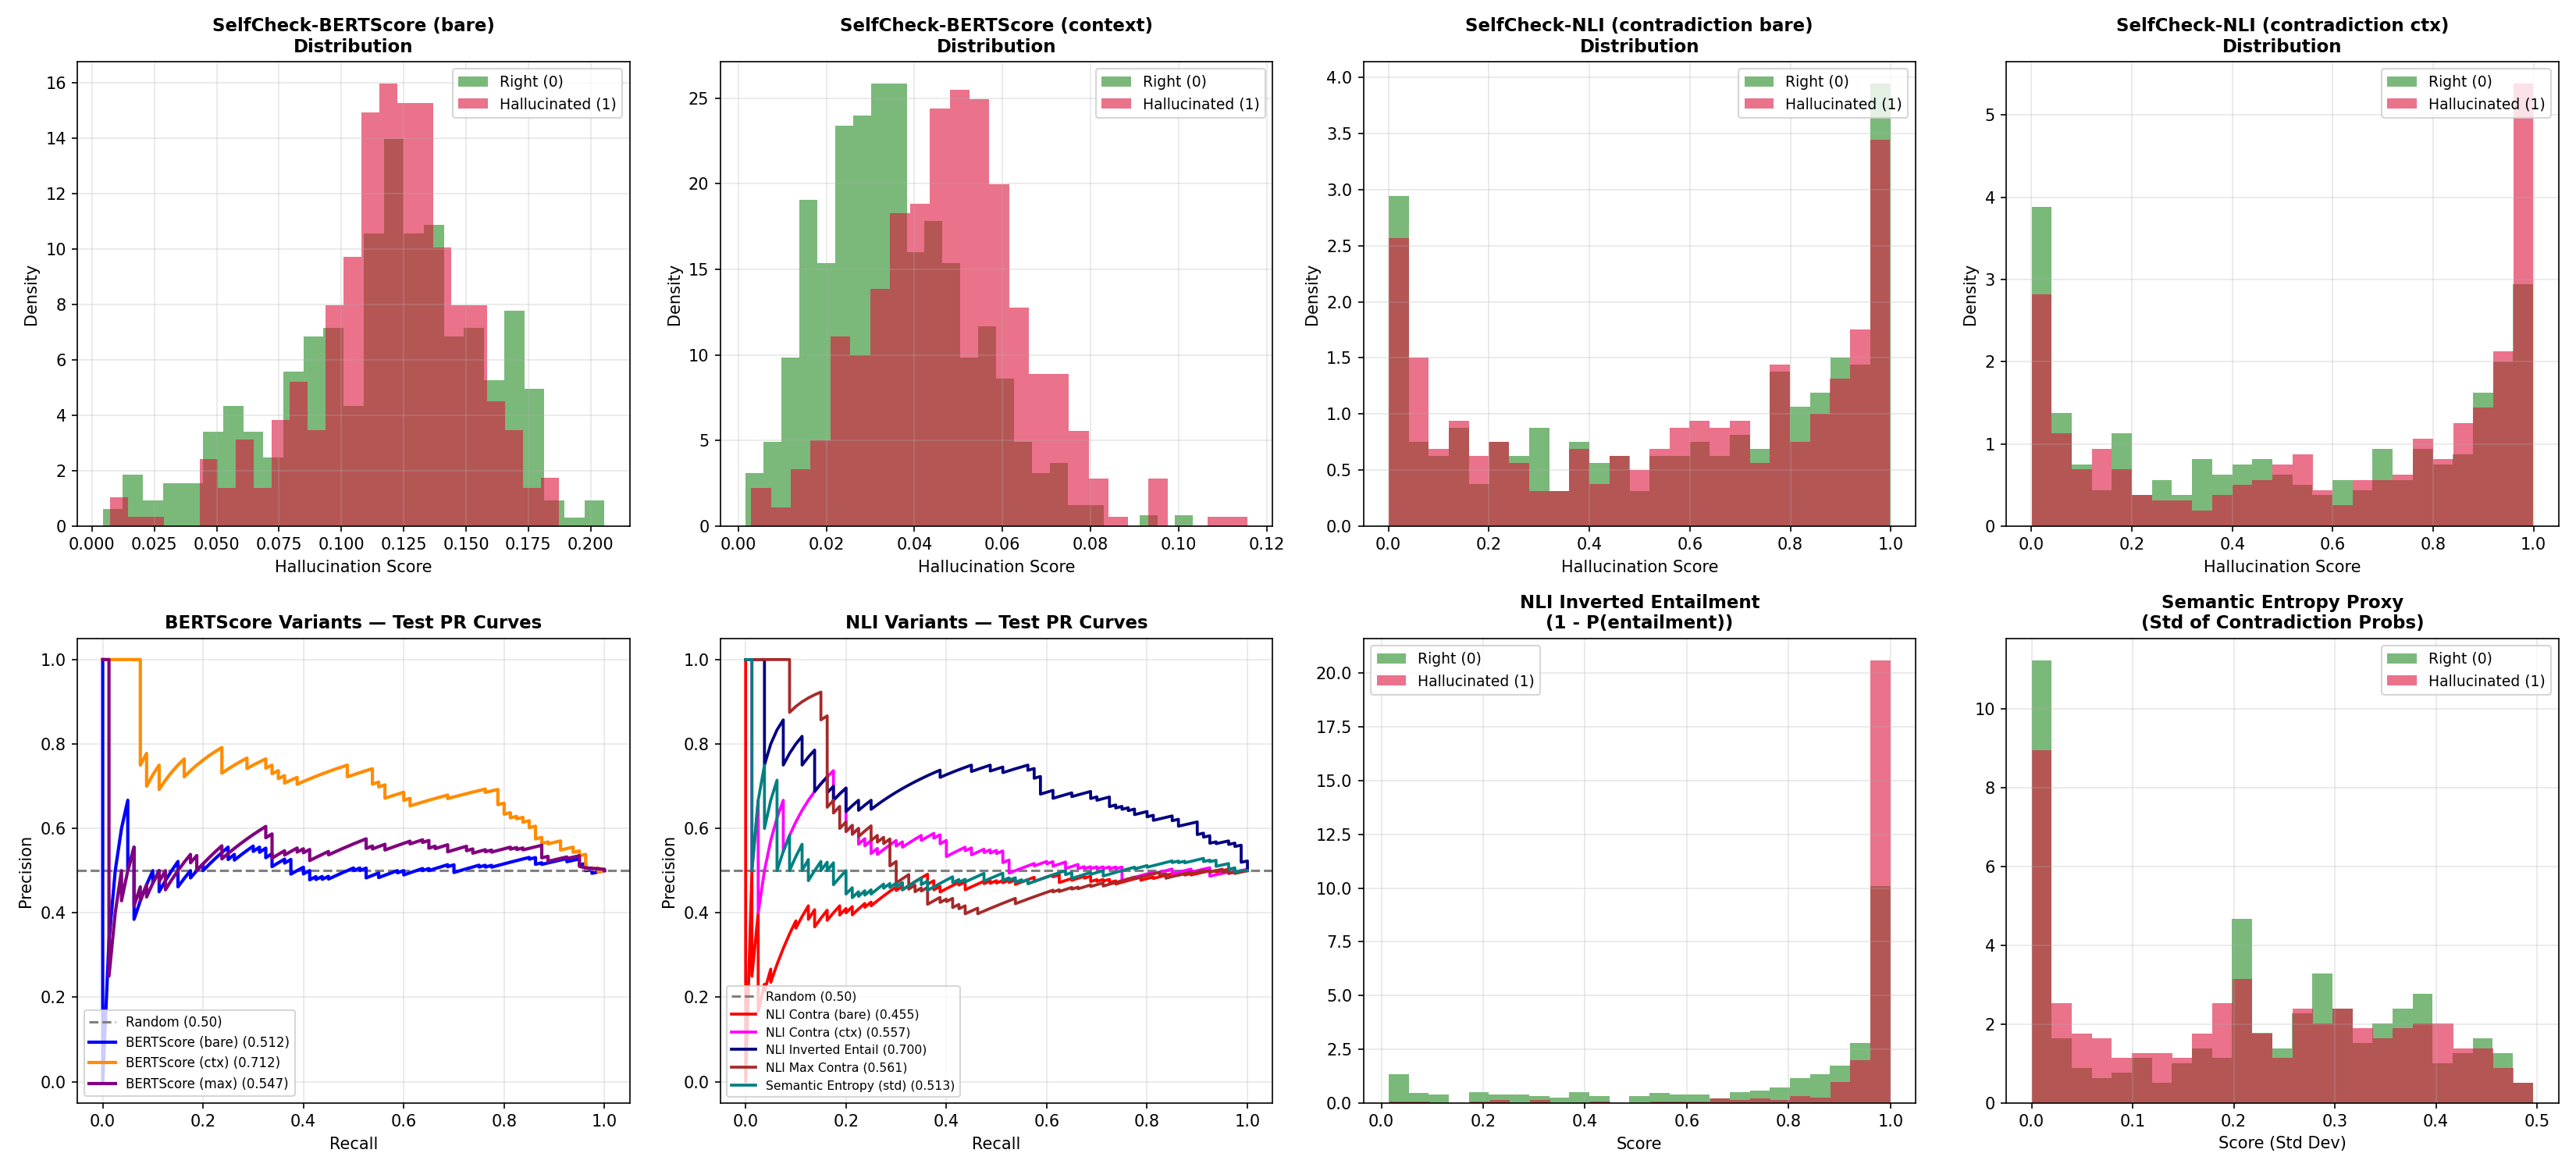

In [8]:
# Cell 8: Display Comparison Table & PR Curves Inline
%cd /kaggle/working/NLP_Assignment_2
import os
import pandas as pd
from IPython.display import Image, display

csv_path = "outputs/final_comparison_v2.csv"
if os.path.exists(csv_path):
    print("=== FINAL COMPARISON TABLE (TEST SET AUC-PR WITH 95% BOOTSTRAP CI) ===")
    display(pd.read_csv(csv_path))

for plot_file in ["outputs/task3_v2_pr_curves.png", "outputs/task1_v2_plots.png", "outputs/task2_v2_plots.png"]:
    if os.path.exists(plot_file):
        print(f"\nPlot: {plot_file}")
        display(Image(filename=plot_file))

---
## Download Results (Checkpoints, Outputs & Models as ZIP)

In [9]:
# Cell 9: Package all Checkpoints, Models, and Outputs into a single ZIP for 1-click download
%cd /kaggle/working/NLP_Assignment_2
import os
from IPython.display import FileLink, display

zip_path = "/kaggle/working/nlp_assignment_2_results.zip"
!zip -q -r {zip_path} checkpoints/ outputs/

if os.path.exists(zip_path):
    size_mb = os.path.getsize(zip_path) / (1024 * 1024)
    print(f"✓ Results archive created: {zip_path} ({size_mb:.2f} MB)")
    print("Click link below to download directly to your computer:")
    display(FileLink("nlp_assignment_2_results.zip"))

print("\n=== Verification of Generated Checkpoints ===")
!ls -lh checkpoints/

print("\n=== Verification of Generated Outputs ===")
!ls -lh outputs/

/kaggle/working/NLP_Assignment_2
✓ Results archive created: /kaggle/working/nlp_assignment_2_results.zip (1.17 MB)
Click link below to download directly to your computer:


/kaggle/working/NLP_Assignment_2/nlp_assignment_2_results.zip


=== Verification of Generated Checkpoints ===
total 984K
-rw-r--r-- 1 root root 355K Nov  6 18:38 task1_v2_features.json
-rw-r--r-- 1 root root 261K Nov  6 18:49 task2_resamples_v2.json
-rw-r--r-- 1 root root 361K Nov  6 18:59 task2_v2_scores.json

=== Verification of Generated Outputs ===
total 1.2M
-rw-r--r-- 1 root root  278 Nov  6 18:35 final_comparison.csv
-rw-r--r-- 1 root root  270 Nov  6 19:00 final_comparison_v2.csv
-rw-r--r-- 1 root root 113K Nov  6 18:35 task1_plots.png
-rw-r--r-- 1 root root  572 Nov  6 18:35 task1_results.json
-rw-r--r-- 1 root root 426K Nov  6 18:38 task1_v2_plots.png
-rw-r--r-- 1 root root 1.1K Nov  6 18:38 task1_v2_results.json
-rw-r--r-- 1 root root 105K Nov  6 18:35 task2_plots.png
-rw-r--r-- 1 root root 1.4K Nov  6 18:35 task2_results.json
-rw-r--r-- 1 root root 276K Nov  6 18:59 task2_v2_plots.png
-rw-r--r-- 1 root root 4.3K Nov  6 18:59 task2_v2_results.json
-rw-r--r-- 1 root root 1.5K Nov  6 18:35 task3_meta_classifier.joblib
-rw-r--r-- 1 root ro